<a href="https://colab.research.google.com/github/mahajanprachii/Vehicle-Fuel-Consumption-Emission-Analysis/blob/main/Vehicle_Fuel_Emission_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer



In [3]:
df=pd.read_csv('/content/CO2 Emissions_Canada.csv')

In [4]:
X = df.drop("CO2 Emissions(g/km)", axis=1)
y = df["CO2 Emissions(g/km)"]

print(X.shape)
print(y.shape)

(7385, 11)
(7385,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [6]:
numerical_columns = X.select_dtypes(include=np.number).columns
categorical_columns = X.select_dtypes(exclude=np.number).columns

print(numerical_columns)
print(categorical_columns)


Index(['Engine Size(L)', 'Cylinders', 'Fuel Consumption City (L/100 km)',
       'Fuel Consumption Hwy (L/100 km)', 'Fuel Consumption Comb (L/100 km)',
       'Fuel Consumption Comb (mpg)'],
      dtype='object')
Index(['Make', 'Model', 'Vehicle Class', 'Transmission', 'Fuel Type'], dtype='object')


ENCODING AND SCALING


In [7]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_columns),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_columns)
    ]
)

In [8]:
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)


In [9]:
pca = PCA(n_components=0.95)

X_train_pca = pca.fit_transform(X_train_processed)
X_test_pca = pca.transform(X_test_processed)

In [10]:
# Number of features before PCA
print("Original number of processed features:", X_train_processed.shape[1])

# Number of features/components after PCA
print("Number of PCA components retained:", pca.n_components_)

# Shape of PCA data
print("X_train_pca shape:", X_train_pca.shape)
print("X_test_pca shape:", X_test_pca.shape)

# Total variance retained
print("Total variance retained:",
      np.sum(pca.explained_variance_ratio_))

Original number of processed features: 2016
Number of PCA components retained: 429
X_train_pca shape: (5908, 429)
X_test_pca shape: (1477, 429)
Total variance retained: 0.9500209483695011


In [11]:
# 33rd and 66th percentile of training CO2 emissions

q1 = y_train.quantile(1/3)
q2 = y_train.quantile(2/3)

print("Low/Medium boundary:", q1)
print("Medium/High boundary:", q2)

Low/Medium boundary: 221.0
Medium/High boundary: 273.0


In [12]:
def create_classes(y):
    return pd.cut(
        y,
        bins=[-np.inf, q1, q2, np.inf],
        labels=["Low", "Medium", "High"]
    )

y_train_class = create_classes(y_train)
y_test_class = create_classes(y_test)

In [13]:
from sklearn.svm import SVC

In [14]:
svm = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

In [15]:
svm.fit(X_train_pca, y_train_class)

SVC()

In [16]:
y_pred = svm.predict(X_test_pca)

In [17]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
accuracy = accuracy_score(y_test_class, y_pred)

print("SVM Accuracy:", accuracy)

SVM Accuracy: 0.970209884901828


In [18]:
cm = confusion_matrix(
    y_test_class,
    y_pred,
    labels=["Low", "Medium", "High"]
)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[501  16   1]
 [  9 480   8]
 [  0  10 452]]


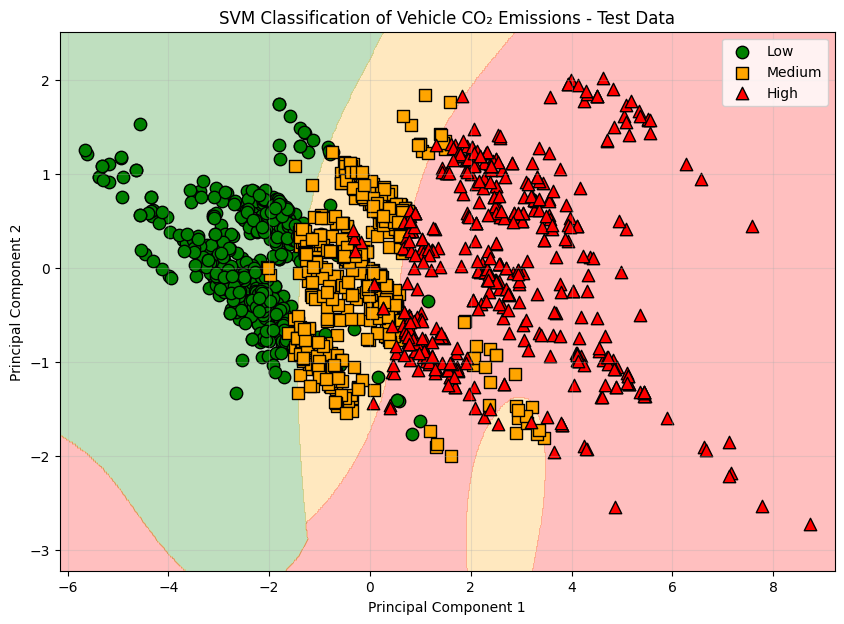

In [20]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.svm import SVC

X = X_test_pca[:, :2]

model = SVC(kernel='rbf', C=1.0, gamma='scale')
model.fit(X_train_pca[:, :2], y_train_class)

y_pred = model.predict(X)

# Create grid
x_min = X[:, 0].min() - 0.5
x_max = X[:, 0].max() + 0.5
y_min = X[:, 1].min() - 0.5
y_max = X[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

# Predict grid points
Z = model.predict(np.c_[xx.ravel(), yy.ravel()])

# Map string labels to numbers for plotting contours
label_map = {'Low': 0, 'Medium': 1, 'High': 2}
Z = np.array([label_map[val] for val in Z])
Z = Z.reshape(xx.shape)

plt.figure(figsize=(10, 7))

# Background contour using numeric representation
plt.contourf(
    xx, yy, Z,
    alpha=0.25,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=['green', 'orange', 'red']
)

# Test points
plt.scatter(
    X[y_test_class == 'Low', 0],
    X[y_test_class == 'Low', 1],
    color='green',
    marker='o',
    label='Low',
    edgecolor='black',
    s=80
)

plt.scatter(
    X[y_test_class == 'Medium', 0],
    X[y_test_class == 'Medium', 1],
    color='orange',
    marker='s',
    label='Medium',
    edgecolor='black',
    s=80
)

plt.scatter(
    X[y_test_class == 'High', 0],
    X[y_test_class == 'High', 1],
    color='red',
    marker='^',
    label='High',
    edgecolor='black',
    s=80
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('SVM Classification of Vehicle CO₂ Emissions - Test Data')

plt.legend()
plt.grid(True, alpha=0.3)
plt.show()